In [ ]:
# 1. Install & Import
!pip install ultralytics roboflow
from ultralytics import YOLO
from roboflow import Roboflow
import os

# 2. Get the Multi-Domain Dataset (Already labeled for you)
# This one contains Concrete, Bridges, and Roads in one go!
rf = Roboflow(api_key="ICPlDyW4dROGrHZeWhkA")
project = rf.workspace("university-bswxt").project("crack-bphdr")
dataset = project.version(2).download("yolov8")

from ultralytics import YOLO

# 1. Load the model
model = YOLO('yolov8n.pt')

# 2. Train with robust, valid augmentation settings
results = model.train(pp
    data=f"{dataset.location}/data.yaml",
    epochs=50,          # Fast but enough for 2k images
    imgsz=640,
    batch=16,           # Optimized for T4 GPU
    # --- ANTI-OVERFIT SETTINGS (FIXED) ---
    mosaic=1.0,         # Mixes 4 images (prevents background memorization)
    mixup=0.1,          # Blends images (adds noise)
    hsv_h=0.015,        # Randomize hue
    hsv_s=0.7,          # Randomize saturation
    hsv_v=0.4,          # Randomize brightness (handles different lighting)
    translate=0.1,      # Randomly shifts image (handles off-center cracks)
    patience=10,        # Early stopping: saves time if it's done early
    # ------------------------------------
    name='crackscan_v3_robust'
)

# 3. Download the result
from google.colab import files
files.download(f"runs/detect/crackscan_v3_robust/weights/best.pt")
print("✅ FIXED! Training started. Weight file will download when done.")


# 4. Download weights
from google.colab import files
files.download(f"runs/detect/crackscan_v2_robust/weights/best.pt")
print("🚀 Training Complete! Weight file downloading...")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.5/169.5 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 74.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 100.7 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.92
    Uninstalling opencv-python-headless-4.13.0.92:
      Successfully uninstalled opencv-python-headless-4.13.0.92
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings w


Extracting Dataset Version Zip to crack-2 in yolov8:: 100%|██████████| 8070/8070 [00:00<00:00, 8589.06it/s]


Ultralytics 8.4.33 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/crack-2/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=crackscan_v3_robust, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10, p

KeyboardInterrupt: 

Evaluating model performance on the Validation Set...
Ultralytics 8.4.33 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1033.1±324.1 MB/s, size: 33.5 KB)
val: Scanning /content/crack-2/valid/labels.cache... 200 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 49.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.6it/s 5.0s
                   all        200        249      0.784      0.714      0.732      0.464
Speed: 3.2ms preprocess, 6.0ms inference, 0.0ms loss, 4.0ms postprocess per image
Results saved to /content/runs/detect/val2

--- PERFORMANCE METRICS ---
Mean Average Precision (mAP50): 0.7324
Mean Average Precision (mAP50-95): 0.4643
Precision: 0.7840 (When it predicts a crack, how often is it right?)
Recall: 0.7144 (Out of all real cracks, how many did it find?)

--- VISUAL METRICS ---
These are generated and saved in your ru

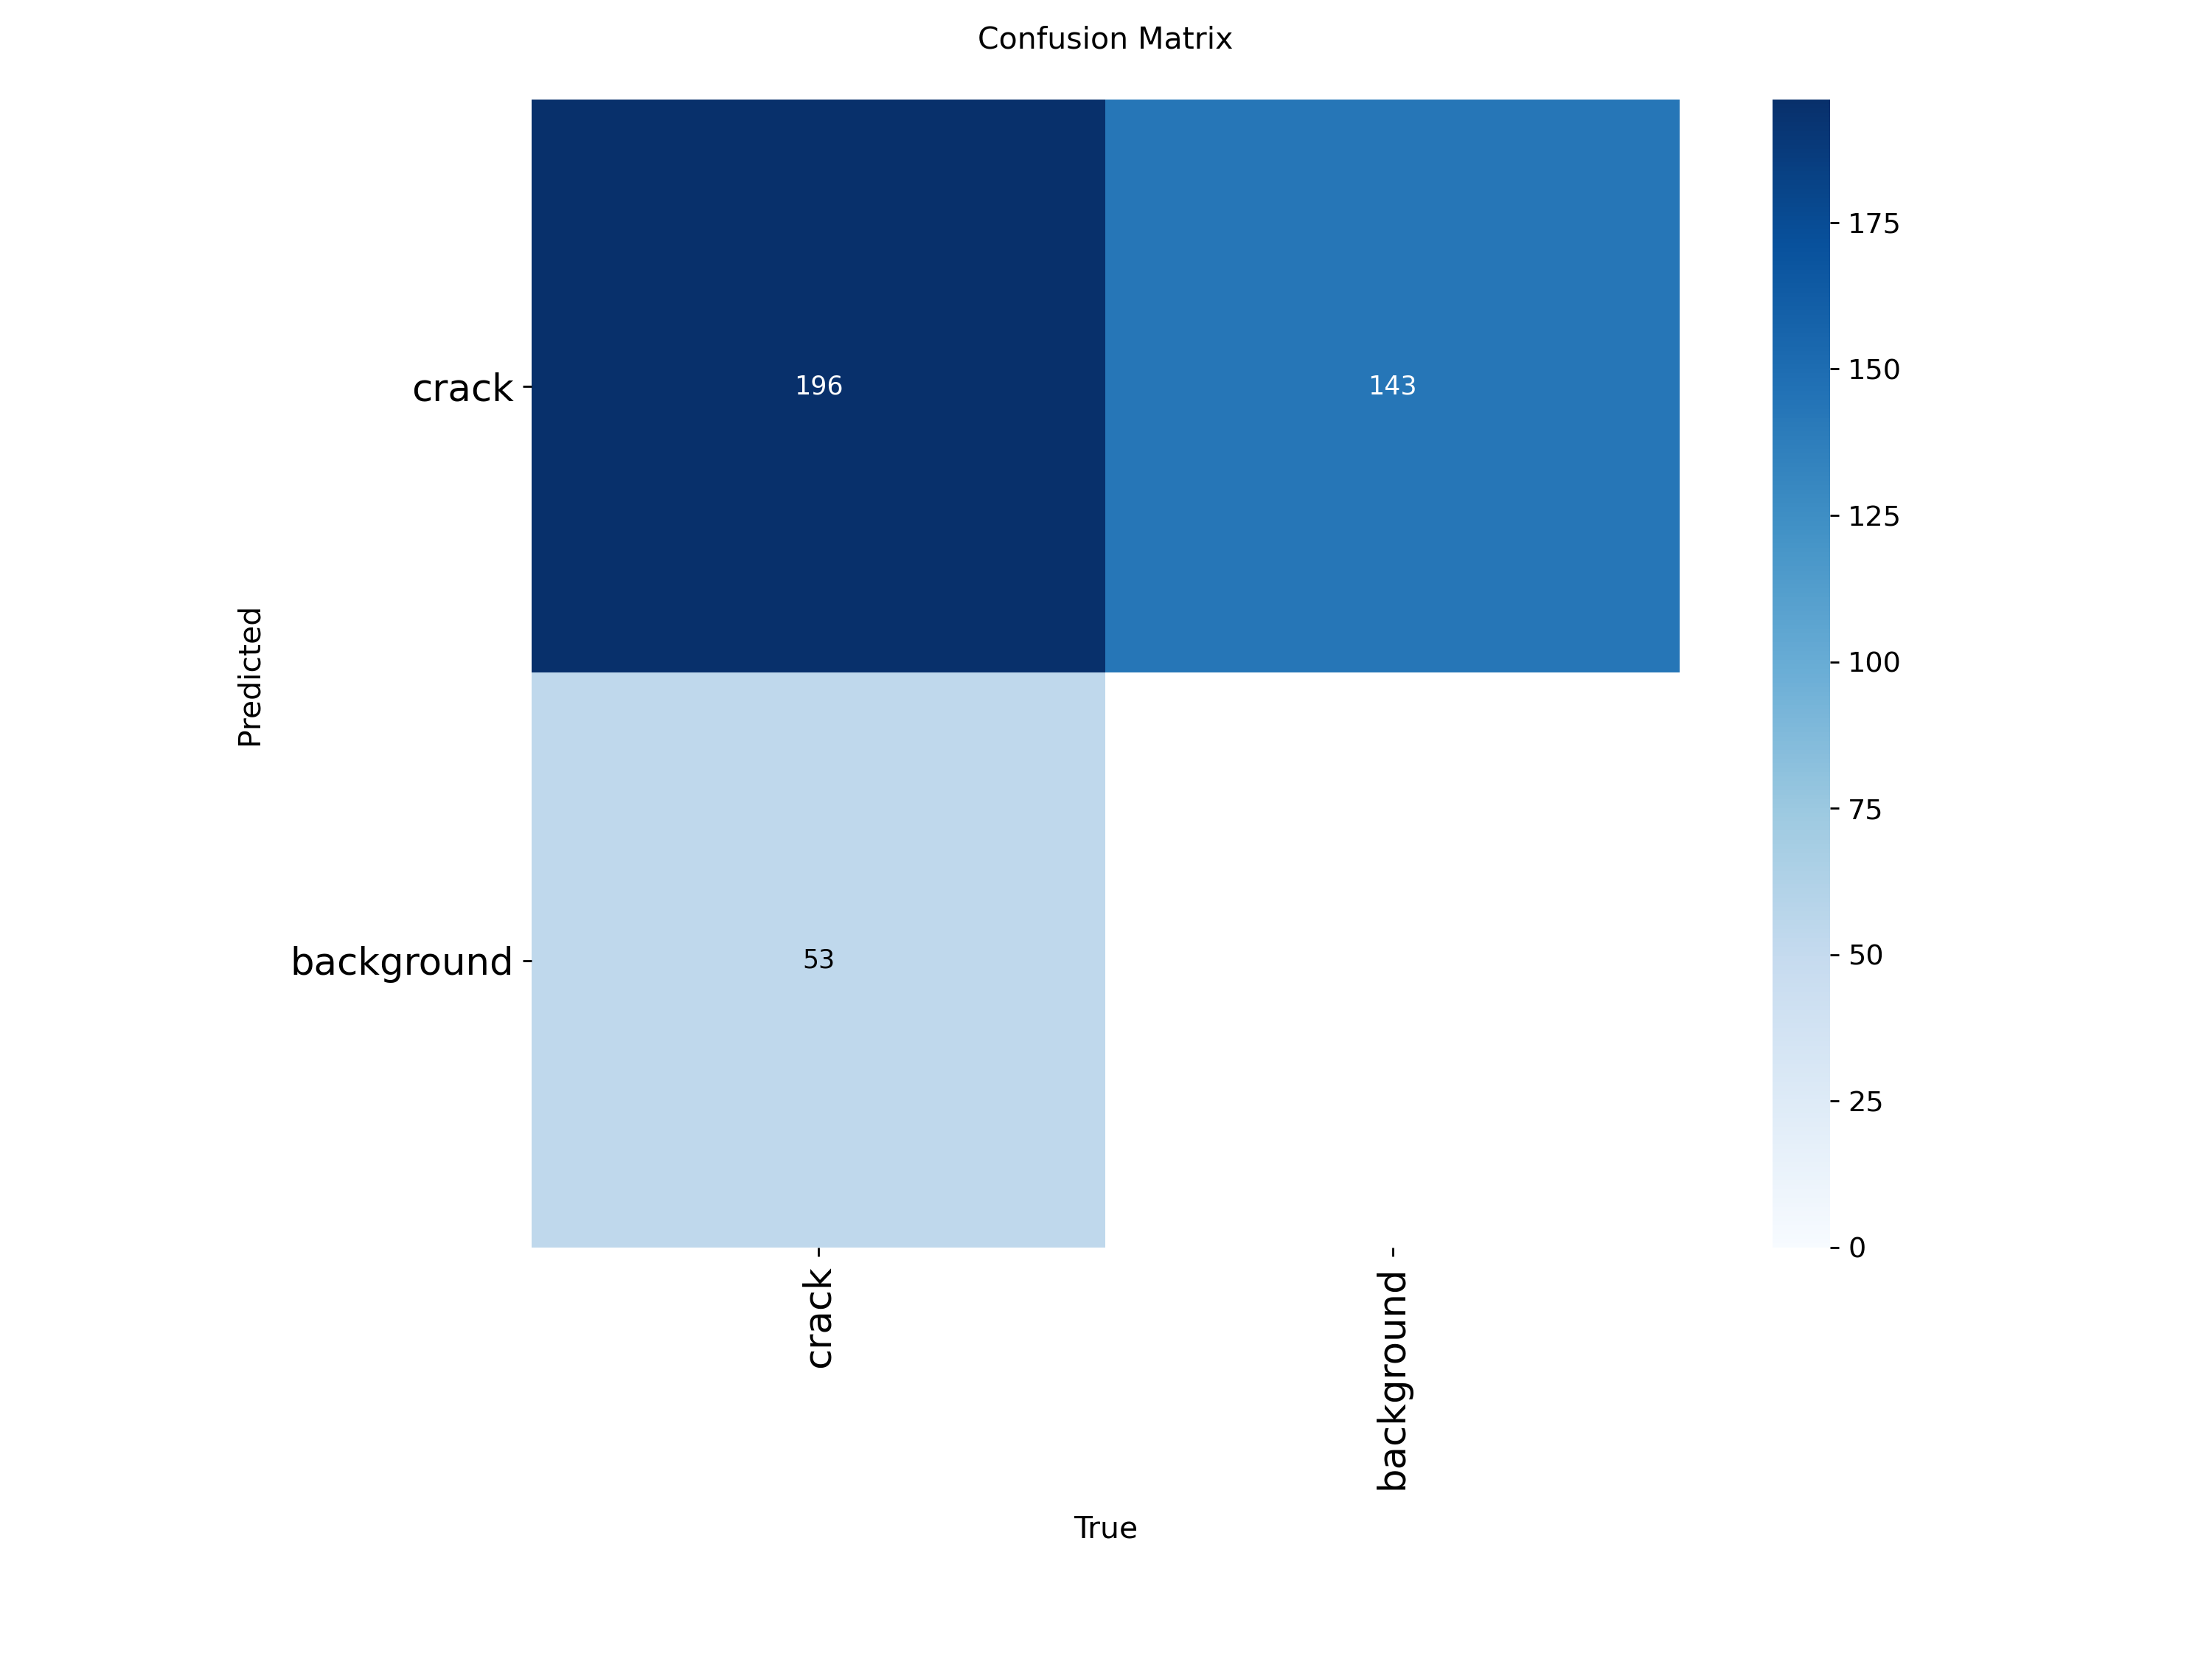

In [ ]:
import pandas as pd
from IPython.display import Image, display

# 1. Run Validation to generate metrics on the test dataset
print("Evaluating model performance on the Validation Set...")
metrics = model.val(
    data=f"{dataset.location}/data.yaml",
    split='val', # Use 'test' if your dataset has a distinct test split
    plots=True   # Automatically generates PR, Confusion Matrix, and F1 plots
)

# 2. Extract and Print Core Numerical Metrics
print("\n--- PERFORMANCE METRICS ---")
print(f"Mean Average Precision (mAP50): {metrics.box.map50:.4f}")
print(f"Mean Average Precision (mAP50-95): {metrics.box.map:.4f}")

# The metrics usually contain lists for each class.
# Taking the mean if you have multiple classes (like Crack, Spall, Defect).
mean_precision = sum(metrics.box.p) / len(metrics.box.p) if len(metrics.box.p) > 0 else 0
mean_recall = sum(metrics.box.r) / len(metrics.box.r) if len(metrics.box.r) > 0 else 0

print(f"Precision: {mean_precision:.4f} (When it predicts a crack, how often is it right?)")
print(f"Recall: {mean_recall:.4f} (Out of all real cracks, how many did it find?)")

# 3. Display the Automatically Generated Plots
print("\n--- VISUAL METRICS ---")
print("These are generated and saved in your runs/detect/ folder by Ultralytics.")

# Find the latest validation run folder
val_dir = metrics.save_dir

# List of plots YOLOv8 usually generates
plots_to_show = [
    "confusion_matrix.png",       # Great for seeing false positives/negatives
    "PR_curve.png",               # The Object Detection equivalent of ROC Curve
    "F1_curve.png",               # Shows the balance between Precision and Recall
    "results.png"                 # Shows loss decreasing over training epochs
]

# Display each image right inside the Colab Notebook
for plot_name in plots_to_show:
    plot_path = f"{val_dir}/{plot_name}"
    if os.path.exists(plot_path):
        print(f"\n=> Displaying: {plot_name}")
        display(Image(filename=plot_path, width=800))
    else:
        # Check training dir if not in val dir (results.png is in train dir)
        train_path = f"runs/detect/crackscan_v3_robust/{plot_name}"
        if os.path.exists(train_path):
             print(f"\n=> Displaying: {plot_name}")
             display(Image(filename=train_path, width=800))


In [ ]:
ExifTool Version Number	13.41
File Name	file.jpg
Directory	.
File Size	153 kB
File Modification Date/Time	2026:04:04 03:10:51+02:00
File Access Date/Time	2026:04:04 03:10:51+02:00
File Inode Change Date/Time	2026:04:04 03:10:51+02:00
File Permissions	-rw-r--r--
File Type	JPEG
File Type Extension	jpg
MIME Type	image/jpeg
JFIF Version	1.01
Resolution Unit	inches
X Resolution	0
Y Resolution	0
Exif Byte Order	Big-endian (Motorola, MM)
Software	Windows 11
Date/Time Original	2026:04:04 06:37:26
Sub Sec Time Original	611
GPS Latitude Ref	North
GPS Longitude Ref	East
Padding	(Binary data 4108 bytes)
Image Width	1280
Image Height	720
Encoding Process	Baseline DCT, Huffman coding
Bits Per Sample	8
Color Components	3
Y Cb Cr Sub Sampling	YCbCr4:2:0 (2 2)
Date/Time Original	2026:04:04 06:37:26.611
GPS Latitude	18 deg 31' 12.29" N
GPS Longitude	73 deg 49' 2.05" E
GPS Position	18 deg 31' 12.29" N, 73 deg 49' 2.05" E
Image Size	1280x720
Megapixels	0.922
this image has exif still fallback generated